# Ejercicio 5 · ¿Qué préstamos no se devolverán?


**Módulo 5072 · SAA · UD3 · 

Un banco quiere saber qué préstamos no se devolverán. Tenemos 614 solicitudes y **el 31 % no se devuelve**.

- **Qué predecimos:** `Loan_Status` = «N» (no se devuelve), que pasamos a 1. Es **clasificación**.
- **Métricas:** elegimos con el **F1** y miramos también el **recall** y el **AUC**.


**Cómo trabajar:**
- Las celdas que dicen **«ya está hecha»**: solo ejecútalas y lee el resultado.
- Las celdas **«# Tu código»**: escribe tú el código. Si te atascas, abre la **Pista 1** (qué hay que hacer) y, si hace falta, la **Pista 2** (el código con huecos `___`).
- Al final miras **en qué variables se fija** el modelo.

## 1 · Preparación

Ejecuta las celdas una a una y mira qué sale. Algunas tienen huecos `___`: rellénalos (ya lo hiciste en los ejercicios anteriores).

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier

DATA = "../data/"
SEMILLA = 42

# 1. Cargar los datos
df = pd.read_csv(DATA + "prestamo.csv")
print(df.shape)

(614, 13)


In [20]:
# 2. X (las pistas) e y: 1 = no devuelve el préstamo, 0 = lo devuelve
X = df.drop(columns=["Loan_ID", "Loan_Status"])      # Loan_ID es un código: no sirve para predecir
y = (df["Loan_Status"] == "N").astype(int)

In [21]:
# 3. Apartamos el 20 % para el test, con el mismo % de impagos en train y en test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEMILLA)

In [22]:
# 4. Huecos en las columnas numéricas: la mediana del TRAIN
numeros = X_train.select_dtypes("number").columns
mediana = X_train[numeros].median()      # ¿de qué trozo sacamos la mediana?
X_train[numeros] = X_train[numeros].fillna(mediana)
X_test[numeros] = X_test[numeros].fillna(mediana)

texto = ["Gender", "Married", "Dependents", "Education", "Self_Employed", "Property_Area"]

# Texto a números con OneHotEncoder: aprende las categorías SOLO con el train
ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
ohe.fit(X_train[texto])      # ¿con qué trozo aprende las categorías?

def codificar(X):
    cod = pd.DataFrame(ohe.transform(X[texto]), columns=ohe.get_feature_names_out(), index=X.index)
    return pd.concat([X.drop(columns=texto), cod], axis=1)

X_train = codificar(X_train)
X_test = codificar(X_test)

In [23]:
# 5. Validación cruzada: el train en 5 trozos
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

In [24]:
# 6. evaluar(): validación cruzada con TRES métricas a la vez.
#    Entrena el modelo 5 veces y mide en el trozo de validación de cada vez. El test no se toca.
def evaluar(nombre, modelo):
    r = cross_validate(modelo, X_train, y_train, cv=cv,
                       scoring=["f1", "recall", "roc_auc"], return_train_score=True)
    return {"modelo": nombre,
            "F1 val": r["test_f1"].mean(),
            "± F1 val": r["test_f1"].std(),
            "recall val": r["test_recall"].mean(),
            "AUC val": r["test_roc_auc"].mean(),
            "F1 train": r["train_f1"].mean()}

def mostrar(resultados):
    return pd.DataFrame(resultados).round(3)

In [25]:
# 7. Baseline: el modelo más tonto, que dice «sí» a todos.
#    Encuentra a todos los positivos (recall 1), pero no ordena nada (AUC 0,5).
p = y_train.mean()          # proporción de positivos
f1_base = 2 * p / (1 + p)   # el F1 de decir siempre que sí
resultados = [{"modelo": "Baseline (todos sí)", "F1 val": f1_base, "± F1 val": np.nan,
               "recall val": 1.0, "AUC val": 0.5, "F1 train": f1_base}]
print("Listo:", len(X_train), "solicitudes para entrenar y validar ·", len(X_test), "para el test")

Listo: 491 solicitudes para entrenar y validar · 123 para el test


**Qué han hecho estas celdas** (en los pasos 3 y 4 has rellenado tú los huecos)
1. Carga las 614 solicitudes.
2. Separa `X` (ingresos, cantidad pedida, historial de crédito...) e `y` (1 = no devuelve).
3. Aparta el 20 % para el **test**, con `stratify`.
4. Rellena los huecos de los números con la **mediana del train**. Las columnas de texto pasan a 0 y 1 con `OneHotEncoder`, aprendido **solo con el train** (un hueco de texto se queda como una categoría más).
5. Prepara la **validación cruzada** de 5 trozos.
6. Crea `evaluar()` con **tres métricas**.
7. Crea la tabla `resultados` con el **baseline**: decir «no lo devolverá» a todos.

**Cómo leer la tabla** (tres métricas a la vez)
- `F1 val`: equilibrio entre encontrar a los préstamos que no se devuelven y no dar falsas alarmas (0 = fatal, 1 = perfecto). **Es la que usamos para comparar.**
- `± F1 val`: cuánto cambia el F1 de un trozo de validación a otro. Si dos modelos se diferencian menos que esto, es un **empate**.
- `recall val`: de cada 100 préstamos que no se devuelven, a cuántos encuentra (0,70 = 70 de cada 100).
- `AUC val`: si ordena bien de más a menos riesgo, sin fijar ningún umbral (0,5 = al azar, 1 = perfecto).
- `F1 train`: el F1 con los datos que ya ha visto. Si es mucho más alto que `F1 val`, el modelo **memoriza**.

In [26]:
mostrar(resultados)

,modelo,F1 val,± F1 val,recall val,AUC val,F1 train
0,Baseline (todos sí),0.478,NaN,1.0,0.5,0.478


**Fíjate:** ¿Qué recall tiene el baseline? ¿Y qué AUC? ¿Por qué no sirve, aunque encuentre a todos los que no pagan?

*Tu respuesta:*

Recall 1.0 y AUC 0.5. No sirve porque es como tirar una moneda

## 2 · Tu turno: entrena y compara

**Tarea 1 · Un árbol sin límite.** Evalúalo y añádelo a `resultados`.

<details><summary><b>Pista 1</b> · qué hay que hacer</summary>

Llama a `evaluar()` con un nombre y el modelo `DecisionTreeClassifier` sin límite (sin `max_depth`). Añade la fila a `resultados` con `append` y muestra la tabla.

</details>

<details><summary><b>Pista 2</b> · código con huecos (cambia cada <code>___</code>)</summary>

```python
resultados.append(evaluar("Árbol sin límite", ___(random_state=SEMILLA)))
mostrar(resultados)
```

</details>

In [27]:
# Tu código
resultados.append(evaluar("Árbol sin límite", DecisionTreeClassifier(random_state=SEMILLA)))
mostrar(resultados)

,modelo,F1 val,± F1 val,recall val,AUC val,F1 train
0,Baseline (todos sí),0.478,NaN,1.00,0.500,0.478
1,Árbol sin límite,0.543,0.074,0.57,0.669,1.000


**Fíjate:** Compara `F1 train` y `F1 val`. ¿Memoriza?

*Tu respuesta:*

Sí memoriza mucho, F1 train 1.0 y F1 val 0.543 hueco enorme.

**Tarea 2 · Random Forest de 300 árboles.**

<details><summary><b>Pista 1</b> · qué hay que hacer</summary>

El modelo es `RandomForestClassifier` y el número de árboles va en `n_estimators`. `n_jobs=-1` usa todos los núcleos del ordenador: va más rápido.

</details>

<details><summary><b>Pista 2</b> · código con huecos (cambia cada <code>___</code>)</summary>

```python
resultados.append(evaluar("Random Forest", ___(n_estimators=___, random_state=SEMILLA, n_jobs=-1)))
mostrar(resultados)
```

</details>

In [28]:
resultados.append(evaluar("Random Forest", RandomForestClassifier(n_estimators=300, random_state=SEMILLA, n_jobs=-1)))
mostrar(resultados)

,modelo,F1 val,± F1 val,recall val,AUC val,F1 train
0,Baseline (todos sí),0.478,NaN,1.000,0.500,0.478
1,Árbol sin límite,0.543,0.074,0.570,0.669,1.000
2,Random Forest,0.554,0.098,0.454,0.753,1.000


**Fíjate:** ¿Mejora al árbol? ¿La diferencia es mayor que el `±`?

*Tu respuesta:*

Mejora muy poco, de 0.543 a 0.554 solo 0.011 y el ± es 0.074 y 0.098, osea entra dentro del error, no es mejora real.

**Tarea 3 · AdaBoost de 200 árboles.** Árboles de una sola pregunta en fila: cada uno se fija más en los casos que fallaron los anteriores.

<details><summary><b>Pista 1</b> · qué hay que hacer</summary>

El modelo es `AdaBoostClassifier` y el número de árboles va en `n_estimators`.

</details>

<details><summary><b>Pista 2</b> · código con huecos (cambia cada <code>___</code>)</summary>

```python
resultados.append(evaluar("AdaBoost", ___(n_estimators=___, random_state=SEMILLA)))
mostrar(resultados)
```

</details>

In [29]:
# Tu código
resultados.append(evaluar("AdaBoost", AdaBoostClassifier(n_estimators=200, random_state=SEMILLA)))
mostrar(resultados)

,modelo,F1 val,± F1 val,recall val,AUC val,F1 train
0,Baseline (todos sí),0.478,NaN,1.000,0.500,0.478
1,Árbol sin límite,0.543,0.074,0.570,0.669,1.000
2,Random Forest,0.554,0.098,0.454,0.753,1.000
3,AdaBoost,0.571,0.130,0.447,0.750,0.641


**Fíjate:** ¿Mejora al árbol? ¿Memoriza?

*Tu respuesta:*

**Tarea 4 · XGBoost por defecto.**

<details><summary><b>Pista 1</b> · qué hay que hacer</summary>

El modelo es `XGBClassifier`. Sin tocar nada: 100 árboles de hasta 6 preguntas y `learning_rate` 0,3.

</details>

<details><summary><b>Pista 2</b> · código con huecos (cambia cada <code>___</code>)</summary>

```python
resultados.append(evaluar("XGBoost por defecto", ___(random_state=SEMILLA)))
mostrar(resultados)
```

</details>

In [30]:
# Tu código
resultados.append(evaluar("XGBoost por defecto", XGBClassifier(random_state=SEMILLA)))
mostrar(resultados)

,modelo,F1 val,± F1 val,recall val,AUC val,F1 train
0,Baseline (todos sí),0.478,NaN,1.000,0.500,0.478
1,Árbol sin límite,0.543,0.074,0.570,0.669,1.000
2,Random Forest,0.554,0.098,0.454,0.753,1.000
3,AdaBoost,0.571,0.130,0.447,0.750,0.641
4,XGBoost por defecto,0.553,0.087,0.493,0.738,1.000


**Fíjate:** Compara `F1 train` y `F1 val`. ¿Memoriza?

*Tu respuesta:*

Sí memoriza mucho, F1 train 1.000 y F1 val 0.553 hueco grande.

**Tarea 5 · XGBoost con frenos.** Pon:
- `max_depth=3`: árboles pequeños.
- `learning_rate=0.05`: poco caso a cada árbol.
- `n_estimators=300`: como le hacemos poco caso a cada uno, hacen falta más árboles.

<details><summary><b>Pista 1</b> · qué hay que hacer</summary>

Guarda el modelo en la variable `xgb_frenos` (la usaremos en el test) y después pásalo a `evaluar()`.

</details>

<details><summary><b>Pista 2</b> · código con huecos (cambia cada <code>___</code>)</summary>

```python
xgb_frenos = XGBClassifier(max_depth=___, learning_rate=___, n_estimators=___, random_state=SEMILLA)
resultados.append(evaluar("XGBoost con frenos", xgb_frenos))
mostrar(resultados)
```

</details>

In [31]:
# Tu código

xgb_frenos = XGBClassifier(max_depth=3, learning_rate=0.05, n_estimators=300, random_state=SEMILLA)
resultados.append(evaluar("XGBoost con frenos", xgb_frenos))
mostrar(resultados)

,modelo,F1 val,± F1 val,recall val,AUC val,F1 train
0,Baseline (todos sí),0.478,NaN,1.000,0.500,0.478
1,Árbol sin límite,0.543,0.074,0.570,0.669,1.000
2,Random Forest,0.554,0.098,0.454,0.753,1.000
3,AdaBoost,0.571,0.130,0.447,0.750,0.641
4,XGBoost por defecto,0.553,0.087,0.493,0.738,1.000
5,XGBoost con frenos,0.562,0.100,0.480,0.765,0.848


**Fíjate:** Compáralo con el XGBoost por defecto. ¿Memoriza menos? ¿Mejora `F1 val`?

*Tu respuesta:*

Memoriza menos, baja de 1.000 a 0.848 en train. Mejora F1 val de 0.553 a 0.562, mejora 0.009.

## 3 · ¿Cuál elegimos?

Esta celda ya está hecha: ejecútala. Ordena la tabla: el mejor queda arriba.

In [32]:
mostrar(pd.DataFrame(resultados).sort_values("F1 val", ascending=False))

,modelo,F1 val,± F1 val,recall val,AUC val,F1 train
3,AdaBoost,0.571,0.130,0.447,0.750,0.641
5,XGBoost con frenos,0.562,0.100,0.480,0.765,0.848
2,Random Forest,0.554,0.098,0.454,0.753,1.000
4,XGBoost por defecto,0.553,0.087,0.493,0.738,1.000
1,Árbol sin límite,0.543,0.074,0.570,0.669,1.000
0,Baseline (todos sí),0.478,NaN,1.000,0.500,0.478


Contesta:
1. ¿Qué modelo gana?
2. Resta su `F1 val` y el del segundo. ¿La diferencia es mayor que el `±`? ¿Gana o es un empate?
3. ¿Cuál eliges? Si hay empate, elige el más sencillo o el más rápido.

*Tu respuesta:*

1. Gana AdaBoost con F1 val 0.571
2. Segundo XGBoost con frenos 0.562 diferencia 0.009 que es mucho menor que el ± 0.130 y 0.100, así que es empate.
3. Elijo AdaBoost porque empata y es el más sencillo.

## 4 · ¿En qué se fija el modelo?

> **Para entenderlo · Importancia de las variables**
>
> Un Random Forest entrenado guarda en `feature_importances_` cuánto le ha servido cada variable para hacer sus preguntas. Cada número va de 0 a 1 y entre todas suman 1.
>
> - Una variable con importancia alta separa bien los casos.
> - **No dice hacia dónde**: no sabemos si subirla aumenta o baja la predicción.
> - **No dice que sea la causa**: solo que al modelo le sirve para acertar.

**4.1** Entrena un Random Forest de 300 árboles con todo el train y dibuja la importancia de cada variable. El gráfico ya está hecho: solo rellena los huecos.

<details><summary><b>Pista</b></summary>

Para entrenar: `.fit(X_train, y_train)`. La importancia está en `rf.feature_importances_`.

</details>

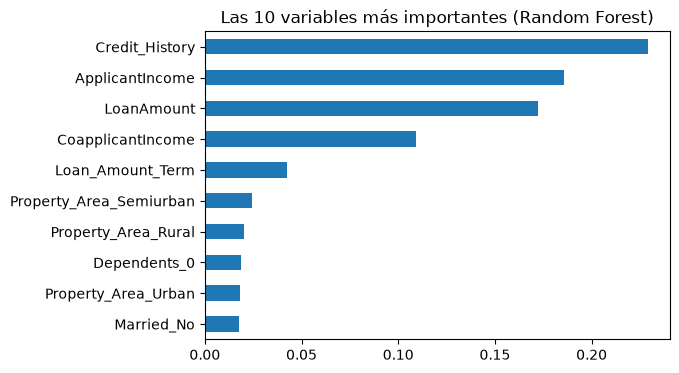

In [33]:
rf = RandomForestClassifier(n_estimators=300, random_state=SEMILLA, n_jobs=-1).fit(X_train, y_train)
importancia = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values()

importancia.tail(10).plot.barh(figsize=(6, 4), title="Las 10 variables más importantes (Random Forest)")
plt.show()

**Cómo leer el gráfico:** cada barra es una variable. Cuanto más larga, más le sirve al modelo. La más importante queda arriba.

Contesta:
1. ¿Cuál es la variable más importante? ¿Tiene sentido?
2. ¿Cuáles son la segunda y la tercera?
3. ¿Dónde queda el historial de crédito (`Credit_History`)?

*Tu respuesta:*

1. La más importante es Credit_History y tiene sentido porque si has pagado bien antes es más probable que pagues ahora.

2. Segunda ApplicantIncome y tercera LoanAmount.

3. Credit_History queda primera arriba del todo, la más importante.

## 5 · El test, una sola vez

Esta celda ya está hecha: ejecútala. Entrena el Random Forest y el XGBoost con frenos con todo el train y los prueba en el test, que hasta ahora no habíamos tocado.

In [34]:
from sklearn.metrics import f1_score, recall_score

rf = RandomForestClassifier(n_estimators=300, random_state=SEMILLA, n_jobs=-1).fit(X_train, y_train)
xgb_frenos.fit(X_train, y_train)

for nombre, modelo in [("Random Forest", rf), ("XGBoost con frenos", xgb_frenos)]:
    pred = modelo.predict(X_test)                  # 0 o 1
    prob = modelo.predict_proba(X_test)[:, 1]      # probabilidad de 1
    print(f"{nombre:18s} · F1 test {f1_score(y_test, pred):.3f} · recall {recall_score(y_test, pred):.3f} · AUC {roc_auc_score(y_test, prob):.3f}")

Random Forest      · F1 test 0.585 · recall 0.500 · AUC 0.733
XGBoost con frenos · F1 test 0.559 · recall 0.500 · AUC 0.700


**Fíjate:** ¿El resultado del test se parece al de validación (`F1 val`)? Si se parece, la validación nos dijo la verdad.

*Tu respuesta:*

Sí se parece. Random Forest val 0.554 y test 0.585, XGBoost con frenos val 0.562 y test 0.559, los dos entran dentro del ± así que la validación nos dijo la verdad.

## 6 · Conclusión

En dos o tres frases: ¿qué modelo eliges? ¿Por qué? Usa números de la tabla.

*Tu respuesta:*

Elijo Random Forest porque tiene F1 val 0.554 y F1 test 0.585 que es mejor que XGBoost con frenos con 0.562 y 0.559, y además es más simple.

## 7 · Experimenta: tres pruebas más

Tres pruebas cortas. Van en una tabla aparte, `extra`, para no mezclarlas con la de antes.

**Extra 1 · ¿Cuántos árboles hacen falta?** Esta celda ya está hecha: ejecútala. Entrena Random Forest con 10, 50 y 100 árboles.

In [35]:
extra = []
for n in [10, 50, 100]:
    extra.append(evaluar(f"Random Forest de {n} árboles", RandomForestClassifier(n_estimators=n, random_state=SEMILLA, n_jobs=-1)))
mostrar(extra)

,modelo,F1 val,± F1 val,recall val,AUC val,F1 train
0,Random Forest de 10 árboles,0.541,0.083,0.448,0.735,0.966
1,Random Forest de 50 árboles,0.565,0.120,0.467,0.756,0.998
2,Random Forest de 100 árboles,0.553,0.103,0.447,0.754,1.000


**Fíjate:** ¿Mejora al pasar de 10 a 50 árboles? ¿Y de 50 a 100? ¿Empeora alguna vez al poner más árboles?

*Tu respuesta:*

Mejora de 10 a 50 de 0.541 a 0.565. De 50 a 100 baja de 0.565 a 0.553. No empeora mucho por poner más árboles, se queda parecido.

**Extra 2 · Un árbol con límite.** Un solo árbol, pero de 5 preguntas como máximo (`max_depth=5`). Cambia los `___`.

In [36]:
extra.append(evaluar("Árbol de 5 preguntas", DecisionTreeClassifier(max_depth=5, random_state=SEMILLA)))
mostrar(extra)

,modelo,F1 val,± F1 val,recall val,AUC val,F1 train
0,Random Forest de 10 árboles,0.541,0.083,0.448,0.735,0.966
1,Random Forest de 50 árboles,0.565,0.120,0.467,0.756,0.998
2,Random Forest de 100 árboles,0.553,0.103,0.447,0.754,1.000
3,Árbol de 5 preguntas,0.536,0.100,0.422,0.710,0.685


**Fíjate:** Compáralo con el árbol sin límite de la tabla de antes. ¿Memoriza menos? ¿Llega a los ensembles?

*Tu respuesta:*

Memoriza menos, baja F1 train de 1.000 a 0.685. No llega a los ensambles, se queda en 0.536 y los Random Forest están en 0.541 a 0.565.

**Extra 3 · Mucho caso a cada árbol.** El mismo XGBoost con frenos, pero con `learning_rate=0.5` en lugar de 0,05. Cambia el `___`.

In [ ]:
xgb_rapido = XGBClassifier(max_depth=3, learning_rate=0.5, n_estimators=300, random_state=SEMILLA)
extra.append(evaluar("XGBoost con learning_rate 0,5", xgb_rapido))
mostrar(extra)

,modelo,F1 val,± F1 val,recall val,AUC val,F1 train
0,Random Forest de 10 árboles,0.541,0.083,0.448,0.735,0.966
1,Random Forest de 50 árboles,0.565,0.120,0.467,0.756,0.998
2,Random Forest de 100 árboles,0.553,0.103,0.447,0.754,1.000
3,Árbol de 5 preguntas,0.536,0.100,0.422,0.710,0.685
4,"XGBoost con learning_rate 0,5",0.566,0.104,0.525,0.728,1.000


**Fíjate:** Compáralo con el XGBoost con frenos (0,05). ¿Memoriza más? ¿Mejora o empeora `F1 val`?

*Tu respuesta:*

Memoriza más, F1 train sube de 0.848 a 1.000. F1 val sube de 0.562 a 0.566, mejora 0.004 que no es nada, está dentro del ±.